<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/1_2_spectral_theorem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.2 · The spectral theorem

*Phase 1 — linear algebra for interpretability*

In notebook 1.1 we saw that a general matrix can have awkward eigenvectors: not perpendicular, sometimes complex, sometimes missing altogether. Symmetric matrices are the well-behaved special case, and they are also the ones that matter most for interpretability, because covariance matrices, Gram matrices ($W^\top W$) and Hessians are all symmetric. The **spectral theorem** says that for a real symmetric matrix $S$:

- every eigenvalue is real,
- eigenvectors belonging to different eigenvalues are perpendicular, and a full set of perpendicular unit eigenvectors always exists,
- so $S = Q\Lambda Q^\top$, with $Q$ orthogonal ($Q^\top Q = I$) and $\Lambda$ diagonal.

As before, each step is a short note followed by one experiment cell. Run them in order and change the numbers freely. All numerics are PyTorch; matplotlib only draws.

1. What makes a matrix symmetric
2. Real eigenvalues, always
3. Perpendicular eigenvectors
4. The picture: an ellipse whose axes are the eigenvectors
5. Spectral decomposition: rotate, stretch, rotate back
6. The quadratic form: eigenvalues as peaks and valleys
7. Where symmetric matrices come from
8. What the theorem doesn't pin down

## Setup

Same conventions as 1.1: double precision, and a fixed colour for each role. Grey is the input space, blue is what the matrix produces, and orange and purple are the first and second eigenvector.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

C_IN, C_OUT = "#6b7280", "#2563eb"          # input space (grey), transformed output (blue)
C_V1, C_V2 = "#d97706", "#9333ea"           # first and second eigenvector (orange, purple)
EIG_COLORS = [C_V1, C_V2]

print("torch", torch.__version__)

torch 2.11.0+cpu


## Step 1 · What makes a matrix symmetric

A matrix is symmetric when it equals its transpose, $S = S^\top$. The entry in row $i$, column $j$ matches the entry in row $j$, column $i$, so the matrix is a mirror image of itself across the diagonal. We'll use this one for most of the notebook:

$$S = \begin{pmatrix} 5 & 2 \\ 2 & 2 \end{pmatrix}$$

Symmetric matrices rarely appear by accident. They come from a few standard constructions, which is why they turn up everywhere: averaging a matrix with its transpose, forming $B^\top B$ (all pairwise dot products between the columns of $B$), and computing a covariance matrix. Let's build one of each and check.

In [2]:
S = torch.tensor([[5.0, 2.0],
                  [2.0, 2.0]])
print("S =\n", S)
print("S == Sᵀ ?", torch.equal(S, S.T), "\n")

B = torch.randn(3, 3)
constructions = {
    "(B + Bᵀ) / 2": (B + B.T) / 2,                       # average a matrix with its mirror image
    "BᵀB":          B.T @ B,                             # dot products between the columns of B
    "covariance":   torch.cov(torch.randn(3, 50)),       # 3 variables, 50 samples
}
for name, M in constructions.items():
    print(f"{name:>13} is symmetric: {torch.allclose(M, M.T)}")

S =
 tensor([[5., 2.],
        [2., 2.]])
S == Sᵀ ? True 

 (B + Bᵀ) / 2 is symmetric: True
          BᵀB is symmetric: True
   covariance is symmetric: True


## Step 2 · Real eigenvalues, always

In 1.1 a rotation had complex eigenvalues. For a real symmetric matrix that cannot happen, and the argument is short. Suppose $Sv = \lambda v$ for some possibly complex vector $v \neq 0$, and write $v^*$ for its conjugate transpose. Then

$$v^* S v = \lambda\, v^* v = \lambda \lVert v \rVert^2$$

Take the conjugate transpose of the left-hand side. Since $S$ is real and symmetric, $S^* = S$, so $(v^*Sv)^* = v^*Sv$, and a number equal to its own conjugate is real. As $\lVert v\rVert^2$ is real and positive, $\lambda$ must be real.

Let's test it. For each matrix size we draw thousands of random matrices and ask the general-purpose eigenvalue solver, which is free to return complex numbers, for their eigenvalues. We do this once on the raw matrices and once after symmetrising them as $(G + G^\top)/2$.

n = 2:  general matrices with complex eigenvalues:  29.2%     symmetric:   0.0%
n = 3:  general matrices with complex eigenvalues:  65.9%     symmetric:   0.0%
n = 4:  general matrices with complex eigenvalues:  87.5%     symmetric:   0.0%
n = 5:  general matrices with complex eigenvalues:  97.0%     symmetric:   0.0%
n = 6:  general matrices with complex eigenvalues:  99.5%     symmetric:   0.0%
n = 7:  general matrices with complex eigenvalues: 100.0%     symmetric:   0.0%
n = 8:  general matrices with complex eigenvalues: 100.0%     symmetric:   0.0%

largest imaginary part among all symmetric matrices: 0.0e+00


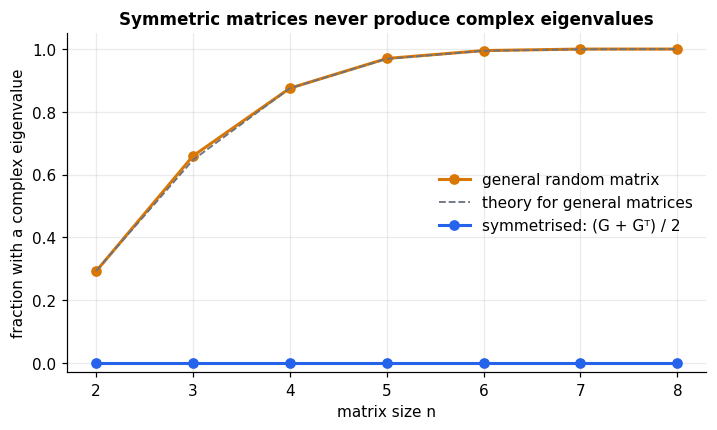

In [3]:
def frac_complex(mats, tol=1e-8):
    """Fraction of matrices in a batch with at least one non-real eigenvalue, and the largest imaginary part seen."""
    w = torch.linalg.eigvals(mats)                       # general solver: output is complex
    worst = w.imag.abs().max(dim=-1).values              # largest imaginary part per matrix
    return (worst > tol).double().mean().item(), worst.max().item()


N = 4000
sizes = [2, 3, 4, 5, 6, 7, 8]
frac_gen, frac_sym, max_imag_sym = [], [], 0.0
for n in sizes:
    G = torch.randn(N, n, n)
    f_gen, _ = frac_complex(G)
    f_sym, imag = frac_complex((G + G.transpose(-1, -2)) / 2)
    frac_gen.append(f_gen); frac_sym.append(f_sym); max_imag_sym = max(max_imag_sym, imag)
    print(f"n = {n}:  general matrices with complex eigenvalues: {f_gen:6.1%}     symmetric: {f_sym:6.1%}")

print(f"\nlargest imaginary part among all symmetric matrices: {max_imag_sym:.1e}")
assert max_imag_sym < 1e-8 and max(frac_sym) == 0.0

# Known result for Gaussian random matrices: P(all eigenvalues real) = 2^(-n(n-1)/4)
theory = [1 - 2 ** (-n * (n - 1) / 4) for n in sizes]
assert all(abs(a - b) < 0.04 for a, b in zip(frac_gen, theory))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(sizes, frac_gen, "o-", color=C_V1, lw=2, label="general random matrix")
ax.plot(sizes, theory, "--", color=C_IN, lw=1.2, label="theory for general matrices")
ax.plot(sizes, frac_sym, "o-", color=C_OUT, lw=2, label="symmetrised: (G + Gᵀ) / 2")
ax.set_xlabel("matrix size n"); ax.set_ylabel("fraction with a complex eigenvalue")
ax.set_ylim(-0.03, 1.05); ax.legend(frameon=False, loc="center right")
ax.set_title("Symmetric matrices never produce complex eigenvalues")
plt.show()

## Step 3 · Perpendicular eigenvectors

Take eigenvectors $v, w$ with different eigenvalues $\lambda \neq \mu$. We can compute $v^\top S w$ in two ways:

$$v^\top S w = v^\top(\mu w) = \mu\, v^\top w \qquad\text{and}\qquad v^\top S w = (S^\top v)^\top w = (Sv)^\top w = \lambda\, v^\top w$$

Subtracting gives $(\lambda - \mu)\, v^\top w = 0$, and since $\lambda \neq \mu$ the dot product $v^\top w$ must be zero. So eigenvectors of a symmetric matrix for different eigenvalues are perpendicular. The full theorem also covers repeated eigenvalues, where perpendicular eigenvectors can still be *chosen*; we come back to that in 1.4.

For symmetric matrices PyTorch has `torch.linalg.eigh`, which guarantees real eigenvalues and orthonormal eigenvectors. It returns the eigenvalues in ascending order, so we wrap it to put the largest first, as in 1.1. Then we check the claim on $S$ and compare with the non-symmetric matrix $A$ from 1.1, whose eigenvectors met at 71.6°.

In [4]:
def eig_sym(S):
    """Eigen-decomposition of a symmetric matrix, largest eigenvalue first. Columns of Q are orthonormal eigenvectors."""
    lam, Q = torch.linalg.eigh(S)                        # ascending order
    order = lam.argsort(descending=True)
    return lam[order], Q[:, order]


lam, Q = eig_sym(S)
print("eigenvalues of S:", lam)
for i in range(2):
    q = Q[:, i]
    resid = (S @ q - lam[i] * q).norm().item()
    print(f"λ{i+1} = {lam[i]:.4f}   q{i+1} = {q.tolist()}   ‖Sq − λq‖ = {resid:.1e}")
    assert resid < 1e-10

dot = (Q[:, 0] @ Q[:, 1]).item()
print(f"\nq₁ · q₂ = {dot:.1e}   →   angle = {math.degrees(math.acos(abs(dot))):.1f}°")
assert abs(dot) < 1e-12 and torch.allclose(lam, torch.tensor([6.0, 1.0]))

# the non-symmetric matrix from notebook 1.1, for contrast
A = torch.tensor([[2.0, 1.0], [0.5, 1.5]])
VA = torch.linalg.eig(A).eigenvectors.real
cos_A = (VA[:, 0] @ VA[:, 1]).abs()
print(f"non-symmetric A from 1.1: angle between eigenvectors = {math.degrees(math.acos(cos_A.item())):.1f}°")

eigenvalues of S: tensor([6., 1.])
λ1 = 6.0000   q1 = [-0.8944271909999159, -0.4472135954999579]   ‖Sq − λq‖ = 0.0e+00
λ2 = 1.0000   q2 = [0.4472135954999579, -0.8944271909999159]   ‖Sq − λq‖ = 1.7e-16

q₁ · q₂ = 0.0e+00   →   angle = 90.0°
non-symmetric A from 1.1: angle between eigenvectors = 71.6°


Nothing here depended on the matrix being 2×2. Let's check a random symmetric 6×6: the six eigenvectors should be mutually perpendicular, which says exactly that $Q^\top Q = I$.

In [5]:
n = 6
Z = torch.randn(n, n)
S6 = (Z + Z.T) / 2
lam6, Q6 = eig_sym(S6)

print("eigenvalues:", lam6)
print("max |QᵀQ − I|   :", (Q6.T @ Q6 - torch.eye(n)).abs().max().item())
print("max |QΛQᵀ − S|  :", (Q6 @ torch.diag(lam6) @ Q6.T - S6).abs().max().item())
assert torch.allclose(Q6.T @ Q6, torch.eye(n)) and torch.allclose(Q6 @ torch.diag(lam6) @ Q6.T, S6)
print("✓ six perpendicular unit eigenvectors, and S = QΛQᵀ")

eigenvalues: tensor([ 2.7468,  1.3255,  0.4677, -0.6179, -1.7414, -2.3064])
max |QᵀQ − I|   : 6.661338147750939e-16
max |QΛQᵀ − S|  : 9.992007221626409e-16
✓ six perpendicular unit eigenvectors, and S = QΛQᵀ


## Step 4 · The picture: an ellipse whose axes are the eigenvectors

Every matrix sends the unit circle to an ellipse. For a symmetric matrix, though, the ellipse's axes line up with the eigenvectors, and the semi-axis lengths are $|\lambda_i|$. This is the perpendicularity from Step 3 seen geometrically: the eigenvectors form a perpendicular pair, each is stretched along its own line, and the result is an "upright" ellipse in that frame.

To test it we need the ellipse's own axes, which we find numerically as the farthest and nearest points of the image curve from the origin. If the claim is right, these points land on the dashed eigen-lines for $S$, but not for the non-symmetric $A$. The true axes of $A$'s ellipse are something else entirely (its singular vectors), which is the subject of Phase 2.

     Symmetric S: farthest point is 6.000 from the origin, nearest 1.000; gap to eigen-lines 0.08°
 Non-symmetric A: farthest point is 2.558 from the origin, nearest 0.977; gap to eigen-lines 13.26°


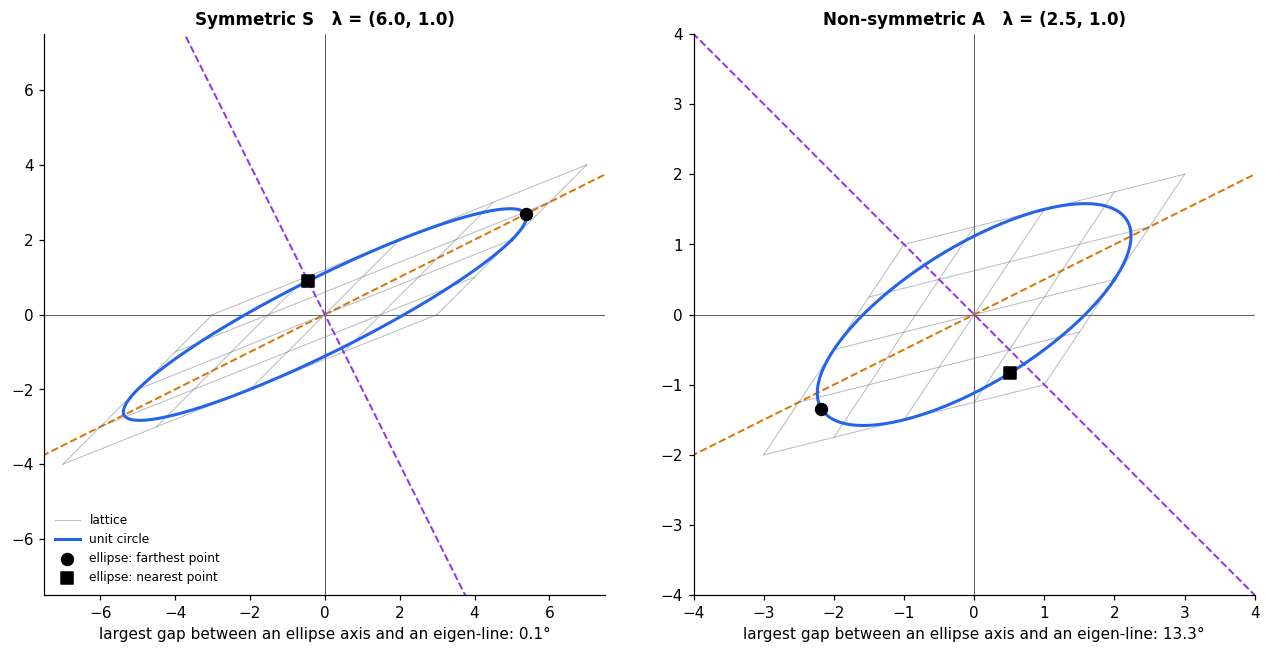

In [6]:
def grid_segments(lim=1.0, step=0.5, n=41):
    """Lattice lines x = k and y = k for k in [-lim, lim], each as a (2, n) tensor of points."""
    t = torch.linspace(-lim, lim, n)
    ones = torch.ones(n)
    segs = []
    for k in torch.arange(-lim, lim + 1e-9, step):
        segs.append(torch.stack([k * ones, t]))
        segs.append(torch.stack([t, k * ones]))
    return segs

theta = torch.linspace(0, 2 * math.pi, 400)
circle = torch.stack([theta.cos(), theta.sin()])


def draw_space(ax, M, title, lim=7.5):
    """Lattice and unit circle after applying M (pass the identity for 'before')."""
    for i, s in enumerate(grid_segments()):
        p = M @ s
        ax.plot(p[0], p[1], color=C_IN, lw=0.7, alpha=0.45, label="lattice" if i == 0 else None)
    c = M @ circle
    ax.plot(c[0], c[1], color=C_OUT, lw=2, label="unit circle")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal"); ax.grid(False)
    ax.axhline(0, color="k", lw=0.4, zorder=0); ax.axvline(0, color="k", lw=0.4, zorder=0)
    ax.set_title(title)


def draw_eigenlines(ax, W, length=12):
    """Dashed line through the origin along each column of W."""
    for i, col in enumerate(EIG_COLORS[: W.shape[1]]):
        w = (W[:, i] / W[:, i].norm()).tolist()
        ax.plot([-length * w[0], length * w[0]], [-length * w[1], length * w[1]],
                color=col, ls="--", lw=1.3, zorder=1)


def extreme_points(M, n=4000):
    """Farthest and nearest points from the origin on the image of the unit circle."""
    t = torch.linspace(0, 2 * math.pi, n)
    img = M @ torch.stack([t.cos(), t.sin()])
    r = img.norm(dim=0)
    return img[:, r.argmax()], img[:, r.argmin()]


def line_angle(u, v):
    """Angle in degrees between two directions, treated as lines (so v and −v are the same)."""
    cross = u[0] * v[1] - u[1] * v[0]
    return math.degrees(math.atan2(cross.abs().item(), (u @ v).abs().item()))


fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
panels = [(axes[0], S, Q, lam, "Symmetric S", 7.5),
          (axes[1], A, VA, torch.linalg.eig(A).eigenvalues.real, "Non-symmetric A", 4.0)]
for ax, M, W, w, name, lim in panels:
    draw_space(ax, M, f"{name}   λ = ({w[0]:.1f}, {w[1]:.1f})", lim=lim)
    draw_eigenlines(ax, W)
    far, near = extreme_points(M)
    ax.scatter(*far.tolist(), s=60, color="black", zorder=6, label="ellipse: farthest point")
    ax.scatter(*near.tolist(), s=60, color="black", marker="s", zorder=6, label="ellipse: nearest point")
    off = max(min(line_angle(far, W[:, i]) for i in range(2)), min(line_angle(near, W[:, i]) for i in range(2)))
    ax.set_xlabel(f"largest gap between an ellipse axis and an eigen-line: {off:.1f}°")
    print(f"{name:>16}: farthest point is {far.norm():.3f} from the origin, nearest {near.norm():.3f}; gap to eigen-lines {off:.2f}°")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

far, near = extreme_points(S)
assert abs(far.norm().item() - 6.0) < 1e-2 and abs(near.norm().item() - 1.0) < 1e-2   # semi-axes are |λ|

## Step 5 · Spectral decomposition: rotate, stretch, rotate back

Stack the orthonormal eigenvectors as the columns of $Q$. Because they are orthonormal, $Q^\top Q = I$, which means $Q^{-1} = Q^\top$: the inverse is just the transpose, with no inversion needed. The decomposition from 1.1, $A = V\Lambda V^{-1}$, therefore becomes

$$S = Q\Lambda Q^\top$$

Read it right to left. $Q^\top$ turns the eigenvectors onto the coordinate axes (a rotation or reflection, which preserves lengths and angles), $\Lambda$ stretches each axis independently, and $Q$ rotates everything back.

Eigenvectors are only defined up to sign, so we are free to choose signs that make $Q$ a proper rotation with determinant $+1$. That makes the picture easier to read, and we can then report the angle.

In [7]:
Q = Q.clone()
if Q[0, 0] < 0: Q[:, 0] = -Q[:, 0]          # eigenvectors are defined up to sign, so we may choose...
if torch.det(Q) < 0: Q[:, 1] = -Q[:, 1]     # ...signs that make Q a proper rotation (det = +1)
Lam = torch.diag(lam)

angle = math.degrees(math.atan2(Q[1, 0].item(), Q[0, 0].item()))
print(f"Q is a rotation by {angle:.2f}°   (det Q = {torch.det(Q).item():+.1f})")
print("\nQ Λ Qᵀ =\n", Q @ Lam @ Q.T)
print("\nQᵀ S Q =\n", Q.T @ S @ Q)

assert torch.allclose(Q @ Lam @ Q.T, S) and torch.allclose(Q.T @ S @ Q, Lam)
assert torch.allclose(torch.linalg.inv(Q), Q.T)
print("\n✓ S = QΛQᵀ, and Q⁻¹ is just Qᵀ")

Q is a rotation by 26.57°   (det Q = +1.0)

Q Λ Qᵀ =
 tensor([[5., 2.],
        [2., 2.]])

Qᵀ S Q =
 tensor([[ 6.0000,  0.0000],
        [-0.0000,  1.0000]])

✓ S = QΛQᵀ, and Q⁻¹ is just Qᵀ


The same decomposition can be written as a sum of rank-one pieces, one per eigenvector:

$$S = \sum_i \lambda_i\, q_i q_i^\top$$

Each $P_i = q_i q_i^\top$ is a projector: it keeps the component of a vector along $q_i$ and discards the rest. The projectors for different eigenvectors are perpendicular to each other, and together they add up to the identity. This form is the natural way to think about low-rank approximation, which returns in Phase 2.

In [8]:
P = [torch.outer(Q[:, i], Q[:, i]) for i in range(2)]        # P_i = q_i q_iᵀ

for i in range(2):
    print(f"P{i+1} =\n", P[i], f"\n   trace = {torch.trace(P[i]).item():.1f}   P² = P: {torch.allclose(P[i] @ P[i], P[i])}\n")
print("P₁ + P₂ = I :", torch.allclose(P[0] + P[1], torch.eye(2)))
print("P₁ P₂ = 0   :", torch.allclose(P[0] @ P[1], torch.zeros(2, 2)))
print("S = λ₁P₁ + λ₂P₂ :", torch.allclose(lam[0] * P[0] + lam[1] * P[1], S))

# keep only the dominant piece: how much of S is lost?
S_rank1 = lam[0] * P[0]
rel_err = ((S - S_rank1).norm() / S.norm()).item()
print(f"\nrank-1 approximation λ₁P₁ misses {rel_err:.1%} of S (relative Frobenius error)")
assert torch.allclose(lam[0] * P[0] + lam[1] * P[1], S)

P1 =
 tensor([[0.8000, 0.4000],
        [0.4000, 0.2000]]) 
   trace = 1.0   P² = P: True

P2 =
 tensor([[ 0.2000, -0.4000],
        [-0.4000,  0.8000]]) 
   trace = 1.0   P² = P: True

P₁ + P₂ = I : True
P₁ P₂ = 0   : True
S = λ₁P₁ + λ₂P₂ : True

rank-1 approximation λ₁P₁ misses 16.4% of S (relative Frobenius error)


Now the rotate–stretch–rotate-back story as a picture. We apply the three factors one at a time to the unit circle and its lattice. The dashed lines follow the two eigenvectors through each stage: they start tilted, are rotated onto the axes, stretched along the axes, and rotated back.

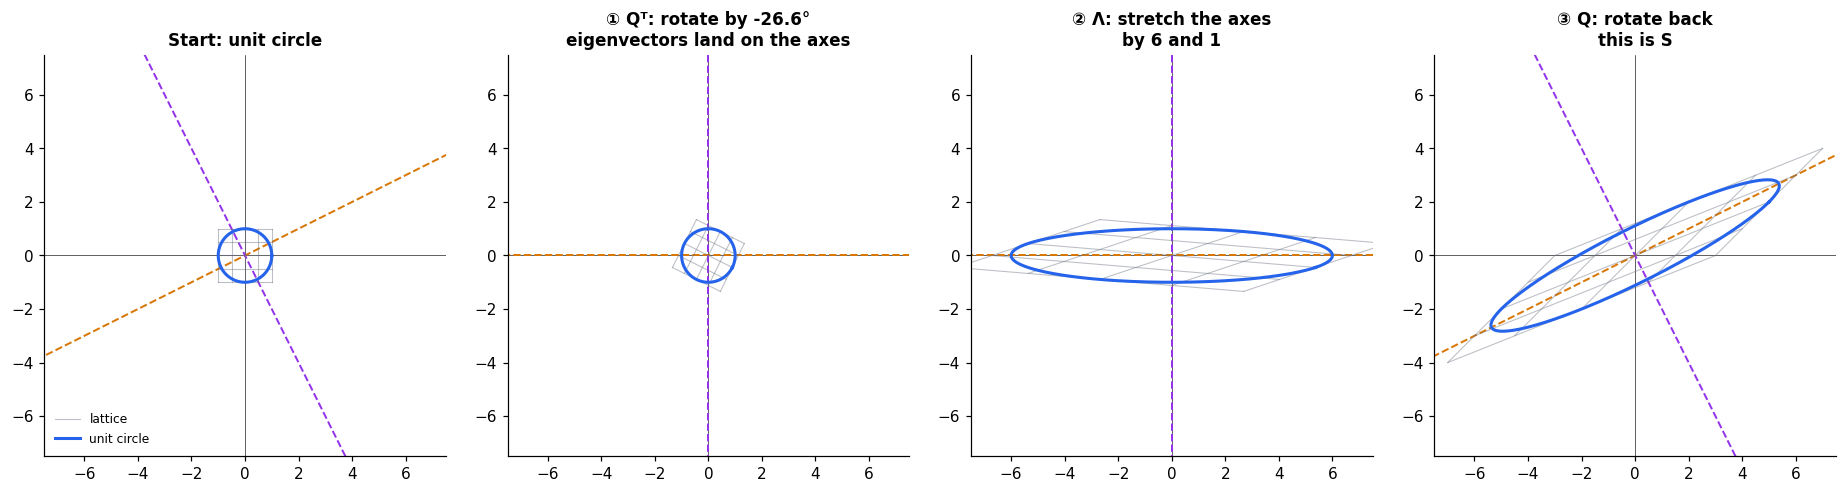

In [9]:
stages = [
    (torch.eye(2),   "Start: unit circle"),
    (Q.T,            f"① Qᵀ: rotate by {-angle:.1f}°\neigenvectors land on the axes"),
    (Lam @ Q.T,      f"② Λ: stretch the axes\nby {lam[0]:.0f} and {lam[1]:.0f}"),
    (Q @ Lam @ Q.T,  "③ Q: rotate back\nthis is S"),
]
assert torch.allclose(stages[3][0], S)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.9))
for ax, (M, title) in zip(axes, stages):
    draw_space(ax, M, title)
    draw_eigenlines(ax, M @ Q)              # where the two eigenvectors have ended up after this stage
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Step 6 · The quadratic form: eigenvalues as peaks and valleys

For a symmetric matrix, $x^\top S x$ is a single number you can compute for every direction $x$. Over unit vectors it is largest along the top eigenvector, where it equals $\lambda_1$, and smallest along the bottom one, where it equals $\lambda_2$. To see why, write $x$ in the eigenbasis at angle $\varphi$ from $v_1$:

$$x^\top S x = \lambda_1\cos^2\varphi + \lambda_2\sin^2\varphi = \tfrac{\lambda_1+\lambda_2}{2} + \tfrac{\lambda_1-\lambda_2}{2}\cos 2\varphi$$

a smooth wave swinging between the two eigenvalues. This is the variational view of PCA that we'll use in 1.3: "the direction of greatest variance" is the top eigenvector of the covariance matrix.

max of xᵀSx on the unit circle: 6.0000 at θ = 26.5°   (λ₁ = 6.0000, v₁ at 26.6°)
min of xᵀSx on the unit circle: 1.0000 at θ = 116.5°   (λ₂ = 1.0000, v₂ at 116.6°)


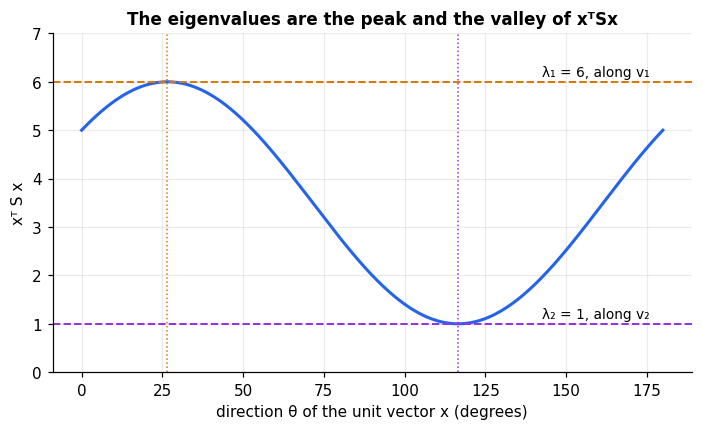

In [11]:
thetas = torch.linspace(0, math.pi, 721)
u = torch.stack([thetas.cos(), thetas.sin()])
rq = (u * (S @ u)).sum(0)                                  # xᵀSx for every unit vector x = (cosθ, sinθ)

th1 = math.atan2(Q[1, 0].item(), Q[0, 0].item())           # direction of the top eigenvector
closed_form = (lam[0] + lam[1]) / 2 + (lam[0] - lam[1]) / 2 * torch.cos(2 * (thetas - th1))
assert torch.allclose(rq, closed_form)

i_max, i_min = rq.argmax().item(), rq.argmin().item()
print(f"max of xᵀSx on the unit circle: {rq.max():.4f} at θ = {math.degrees(thetas[i_max]):.1f}°   (λ₁ = {lam[0]:.4f}, v₁ at {math.degrees(th1):.1f}°)")
print(f"min of xᵀSx on the unit circle: {rq.min():.4f} at θ = {math.degrees(thetas[i_min]):.1f}°   (λ₂ = {lam[1]:.4f}, v₂ at {math.degrees(th1) + 90:.1f}°)")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(torch.rad2deg(thetas), rq, color=C_OUT, lw=2)
ax.axhline(lam[0].item(), color=C_V1, ls="--", lw=1.3)
ax.axhline(lam[1].item(), color=C_V2, ls="--", lw=1.3)
ax.axvline(math.degrees(th1), color=C_V1, ls=":", lw=1.0)
ax.axvline(math.degrees(th1) + 90, color=C_V2, ls=":", lw=1.0)
ax.text(176, lam[0].item() + 0.12, "λ₁ = 6, along v₁", color="black", ha="right", fontsize=9)
ax.text(176, lam[1].item() + 0.12, "λ₂ = 1, along v₂", color="black", ha="right", fontsize=9)
ax.set_xlabel("direction θ of the unit vector x (degrees)"); ax.set_ylabel("xᵀ S x")
ax.set_ylim(0, 7); ax.set_title("The eigenvalues are the peak and the valley of xᵀSx")
plt.show()

## Step 7 · Where symmetric matrices come from

The matrix $G = B^\top B$ is symmetric, and also **positive semi-definite**: $x^\top G x = \lVert Bx\rVert^2 \geq 0$ for every $x$, so none of its eigenvalues can be negative. Its eigenvalues are the squares of $B$'s singular values, which is the bridge to Phase 2. Gram matrices such as $W^\top W$, which we'll meet in the toy models of superposition in Phase 4, and covariance matrices are exactly this kind of matrix.

Not every symmetric matrix is positive semi-definite, though, and the last line below shows one with a negative eigenvalue.

In [14]:
B = torch.randn(8, 3)                       # 8 samples, 3 features
G = B.T @ B

ev = torch.linalg.eigvalsh(G)               # ascending
sv = torch.linalg.svdvals(B)                # descending
print("eigenvalues of BᵀB :", ev.flip(0))
print("singular values²   :", sv ** 2)
assert torch.allclose(ev.flip(0), sv ** 2) and (ev > -1e-12).all()

x = torch.randn(3, 1000)
quad = (x * (G @ x)).sum(0)                 # xᵀGx
norm_sq = ((B @ x) ** 2).sum(0)             # ‖Bx‖²
print("xᵀ(BᵀB)x == ‖Bx‖² for 1000 random x:", torch.allclose(quad, norm_sq))

indefinite = torch.tensor([[1.0, 2.0], [2.0, 1.0]])
print("\nsymmetric but not PSD, eigenvalues:", torch.linalg.eigvalsh(indefinite))

eigenvalues of BᵀB : tensor([17.6945,  3.3790,  3.0644])
singular values²   : tensor([17.6945,  3.3790,  3.0644])
xᵀ(BᵀB)x == ‖Bx‖² for 1000 random x: True

symmetric but not PSD, eigenvalues: tensor([-1.,  3.])


## Step 8 · What the theorem doesn't pin down

The theorem guarantees that an orthonormal eigenbasis exists, not that it is unique. Two kinds of freedom remain. First, each eigenvector is defined only up to sign (a direction is a line, not an arrow), and the order of the eigenvectors is arbitrary as long as $\Lambda$ is reordered to match. Second, if an eigenvalue is repeated, the eigenvectors for it can be rotated freely within their shared plane. Let's confirm both.

In [ ]:
# 1) sign and order freedom
Q_flip = Q * torch.tensor([1.0, -1.0])                     # flip the sign of the second eigenvector
Q_swap, lam_swap = Q[:, [1, 0]], lam[[1, 0]]               # swap the order, and swap Λ to match
print("flipped sign still reconstructs S :", torch.allclose(Q_flip @ Lam @ Q_flip.T, S))
print("swapped order still reconstructs S:", torch.allclose(Q_swap @ torch.diag(lam_swap) @ Q_swap.T, S))

# 2) repeated eigenvalue: the matrix 3·I has λ = 3 twice, and ANY rotated basis diagonalises it
phi = math.radians(30)
R = torch.tensor([[math.cos(phi), -math.sin(phi)], [math.sin(phi), math.cos(phi)]])
M = 3 * torch.eye(2)
print("\nM = 3I: every column of R is an eigenvector for λ = 3:", torch.allclose(M @ R, 3 * R))
print("RᵀMR is diagonal, for any rotation R              :", torch.allclose(R.T @ M @ R, M))

flipped sign still reconstructs S : True
swapped order still reconstructs S: True

M = 3I: every column of R is an eigenvector for λ = 3: True
RᵀMR is diagonal, for any rotation R              : True


## Try it yourself

1. **Build to order.** Construct a symmetric matrix with eigenvalues $3$ and $-1$ along directions at $30°$ and $120°$, using $Q\Lambda Q^\top$. Verify that it is symmetric and that `eig_sym` recovers your eigenvalues.
2. **Symmetrise.** Take a random non-symmetric 5×5 matrix $G$ and compare the eigenvalues of $G$ with those of $(G + G^\top)/2$. What happens to the complex ones?
3. **Peaks and valleys.** For a random symmetric 4×4 matrix, evaluate $x^\top S x$ at 10,000 random unit vectors. Does it ever exceed $\lambda_{\max}$ or fall below $\lambda_{\min}$?
4. **Indefinite ellipse.** Redo Step 4 with $\begin{pmatrix} 1 & 2 \\ 2 & 1 \end{pmatrix}$, whose eigenvalues are $3$ and $-1$. The ellipse axes should still sit on the eigen-lines. What does the negative eigenvalue do to the lattice?

## What to carry forward

- A real symmetric matrix has **real eigenvalues** and **perpendicular eigenvectors**, so $S = Q\Lambda Q^\top$ with $Q^{-1} = Q^\top$.
- Geometrically it sends the unit circle to an ellipse whose axes are the eigenvectors, with lengths $|\lambda_i|$. The map is rotate, stretch along the axes, rotate back.
- Equivalently, $S = \sum_i \lambda_i q_i q_i^\top$: a sum of one-dimensional projectors, each weighted by an eigenvalue.
- The eigenvalues are the peaks and valleys of $x^\top S x$ on the unit circle. This is why PCA picks the top eigenvector of the covariance matrix.
- $B^\top B$ is always symmetric and positive semi-definite, and its eigenvalues are $B$'s squared singular values.
- The eigenbasis is unique only up to sign and order, and not even that when eigenvalues repeat. For interpretability, "a direction" is a line, and a repeated eigenvalue means no single basis is privileged.

**Next, notebook 1.3:** the covariance matrix, and PCA as its eigendecomposition.